# LAB2 - Bài 7

## Chuẩn bị các thư viện cần thiết

In [1]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split

## Download dữ liệu có sẵn trong thư viện sklearn

In [2]:
# The digits dataset
digits = datasets.load_digits()

## Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3

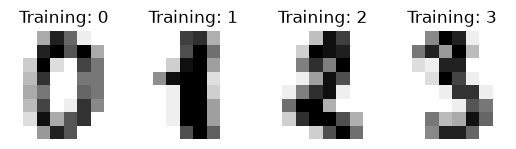

In [3]:
# The data that we are interested in is made of 8x8 images of digits, let's
# have a look at the first 4 images, stored in the `images` attribute of the
# dataset.  If we were working from image files, we could load them using
# matplotlib.pyplot.imread.  Note that each image must have the same size. For these
# images, we know which digit they represent: it is given in the 'target' of
# the dataset.
_, axes = plt.subplots(1, 4)
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Training: %i' % label)
plt.show()

Đặng Phan Duy - 6451071010

## Chuyển đổi mỗi đối tượng hình ảnh – ma trận 8x8 thành ma trận 1x64

In [4]:
# To apply a classifier on this data, we need to flatten the image, to
# turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

## Sử dụng thuật toán cây ID3

In [5]:
# Create a classifier: a decision tree classifier
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)

## Chia dữ liệu thành hai phần: huấn luyện 80%, kiểm thử 20%

In [6]:
# Split data into train and test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False)

## Tiến hành xây dựng cây ID3

In [7]:
# We learn the digits on the first part of the digits
classifier.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",33
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samp

Đặng Phan Duy - 6451071010

## Dự đoán nhãn dữ liệu cho tập kiểm thử

In [8]:
# Now predict the value of the digit on the second part:
predicted = classifier.predict(X_test)

## Biểu diễn một vài kết quả dự đoán

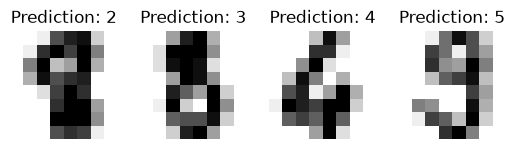

In [9]:
_, axes = plt.subplots(1, 4)
images_and_predictions = list(zip(digits.images[n_samples // 2:], predicted))
for ax, (image, prediction) in zip(axes, images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Prediction: %i' % prediction)
plt.show()

Đặng Phan Duy - 6451071010

## Thông số đạt được của cây ID3

Classification report for classifier DecisionTreeClassifier(criterion='entropy', random_state=33):
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360


Confusion matrix:
[[31  0  0  0  1  0  0  0  1  2]
 [ 0 23  0  2  2  0  0  1  1  7]
 [ 1  2 26  0  0  1  0  3  2  0]
 [ 0  4  2 22  0  4  0  

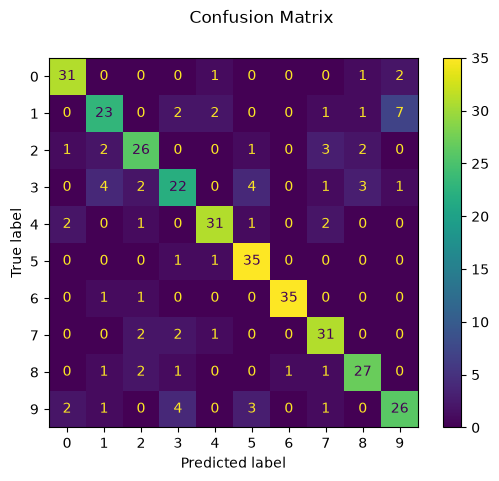

In [10]:
print("Classification report for classifier %s:\n%s\n"
      % (classifier, metrics.classification_report(y_test, predicted)))
disp = metrics.ConfusionMatrixDisplay.from_estimator(classifier, X_test, y_test)
disp.figure_.suptitle("Confusion Matrix")
print("Confusion matrix:\n%s" % disp.confusion_matrix)

Đặng Phan Duy - 6451071010

## Cài đặt thư viện xử lý hình ảnh pillow cho Python và import vào

In [11]:
from PIL import Image, ImageOps
import numpy as np

## Nhận dạng chữ số viết tay thứ 1 (ảnh 'test_image_Bai7.jpg' - chữ số 2)

Đọc hình vào phần mềm

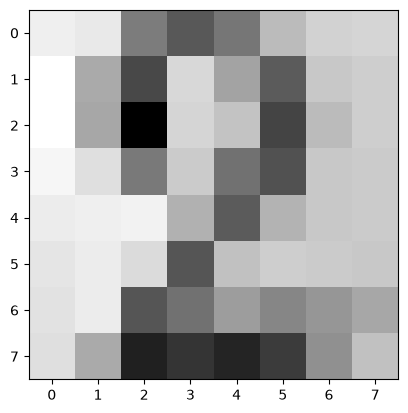

In [12]:
#Open image
img = Image.open('./Dataset/test_image_Bai7.jpg').convert("L").resize((8,8))
#Invert image
img = ImageOps.invert(img)
#Convert to numpy array
im2arr = np.array(img)
#Show
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')

Đặng Phan Duy - 6451071010

Làm rõ nét lại bức ảnh bằng cách phân biệt rõ những giá trị đen, trắng

In [13]:
#Change from 2d array (8x8) to 1d array (1x64)
img1d=im2arr.reshape([1,64])
#normailize black & white image array
img1d[img1d > 109] = 155
img1d[img1d < 110] = 0
img1d

array([[  0,   0, 155, 155, 155,   0,   0,   0,   0,   0, 155,   0,   0,
        155,   0,   0,   0,   0, 155,   0,   0, 155,   0,   0,   0,   0,
        155,   0, 155, 155,   0,   0,   0,   0,   0,   0, 155,   0,   0,
          0,   0,   0,   0, 155,   0,   0,   0,   0,   0,   0, 155, 155,
          0, 155,   0,   0,   0,   0, 155, 155, 155, 155,   0,   0]],
      dtype=uint8)

Đặng Phan Duy - 6451071010

Hình ảnh chữ số sau khi làm rõ

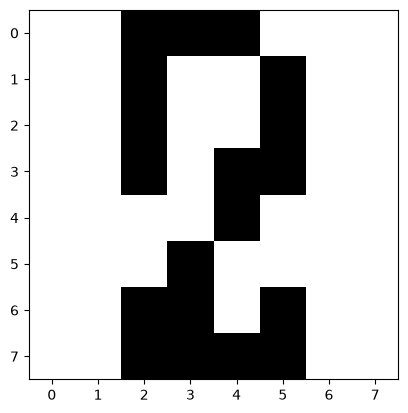

In [14]:
#After normalize
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')

Đặng Phan Duy - 6451071010

Tiến hành nhận diện bằng cây ID3 và in ra kết quả

In [15]:
#Predict label of number
y_pred = classifier.predict(img1d)
print(y_pred)

[2]


Đặng Phan Duy - 6451071010

## Nhận dạng chữ số viết tay thứ 2 (ảnh 'test_image_Bai7(1).jpg' - chữ số 1)

Đọc hình vào phần mềm

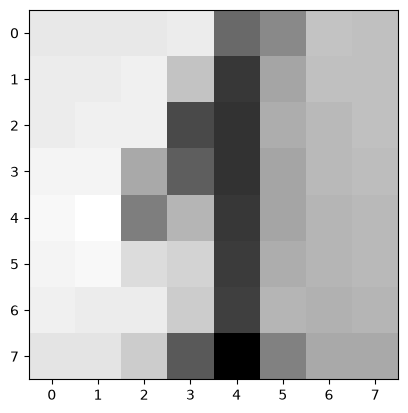

In [16]:
#Open image
img = Image.open('./Dataset/test_image_Bai7(1).jpg').convert("L").resize((8,8))
#Invert image
img = ImageOps.invert(img)
#Convert to numpy array
im2arr = np.array(img)
#Show
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')

Đặng Phan Duy - 6451071010

Làm rõ nét lại bức ảnh bằng cách phân biệt rõ những giá trị đen, trắng

In [17]:
#Change from 2d array (8x8) to 1d array (1x64)
img1d=im2arr.reshape([1,64])
#normailize black & white image array
img1d[img1d > 109] = 155
img1d[img1d < 110] = 0
img1d

array([[  0,   0,   0,   0, 155,   0,   0,   0,   0,   0,   0,   0, 155,
          0,   0,   0,   0,   0,   0, 155, 155,   0,   0,   0,   0,   0,
          0, 155, 155,   0,   0,   0,   0,   0,   0,   0, 155,   0,   0,
          0,   0,   0,   0,   0, 155,   0,   0,   0,   0,   0,   0,   0,
        155,   0,   0,   0,   0,   0,   0, 155, 155,   0,   0,   0]],
      dtype=uint8)

Đặng Phan Duy - 6451071010

Hình ảnh chữ số sau khi làm rõ

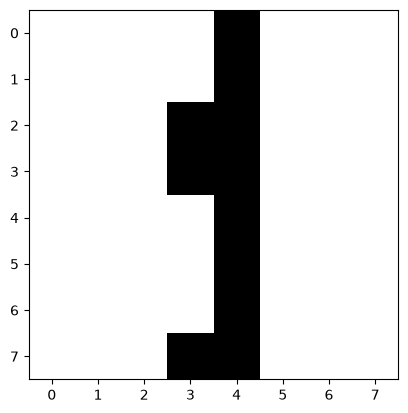

In [18]:
#After normalize
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')

Đặng Phan Duy - 6451071010

Tiến hành nhận diện bằng cây ID3 và in ra kết quả

In [19]:
#Predict label of number
y_pred = classifier.predict(img1d)
print(y_pred)

[1]


Đặng Phan Duy - 6451071010